# Approaching the stability threshold

Notebook 03 studied an unstable labelled quadrilateral, where minimizing over polynomials of fixed degree gave results that depend on the scheme. Here the opposite approach: keep the orbifold (normals and labels) fixed, vary the Kähler class until it becomes unstable, and follow the *genuine* extremal metrics up to the threshold. Every metric along the way is an honest solution, checkable by refinement.

**Summary.** The orbifold is stable for λ < λ* ≈ 4.3176, unstable up to λ** ≈ 7.9074, stable again up to 8. At λ* a single crease becomes balanced: the extremal affine function is extremal for each of the two pieces it cuts off, with zero boundary measure on the cut (the semistable splitting of Donaldson's Conjecture 7.2.3). Its direction is irrational. As λ ↑ λ*, the extremal metrics develop a neck along that crease: arc length across it grows, the circle dual to it shrinks, the base length stays fixed and curvature stays moderate. That points to collapsing, finite-volume ends rather than ALF ends.

In [1]:
%matplotlib inline
import math, time
from fractions import Fraction
import numpy as np
import mpmath
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from extremal import Polygon, viz
from extremal.solver import ExtremalSolver
from extremal.stability import crease_search

## 1. The family

Keep the four normals and the labels of Q₁₂ (notebook 03): bottom edge label 1, the other three label 12. Up to translation and scale the Kähler classes form one parameter, the length λ of the bottom edge:

  P(λ) = { y ≥ 0, x ≥ 0, x + y ≤ λ, x + 4y ≤ 8 },  2 < λ < 8,

with Q₁₂ = P(5). At λ = 8 the right edge shrinks to a point and for λ ≥ 8 the polygon is the fixed triangle T₁ = (0,0), (8,0), (0,2); for λ ≤ 2 the top edge is gone and it is the triangle T₂ = {x, y ≥ 0, x + y ≤ λ}. So P(λ) is a weighted blow-up of T₁ (near λ = 8) or of T₂ (near λ = 2) at a vertex, with exceptional divisor of lattice length (8 − λ)/3, respectively λ − 2 up to scale.

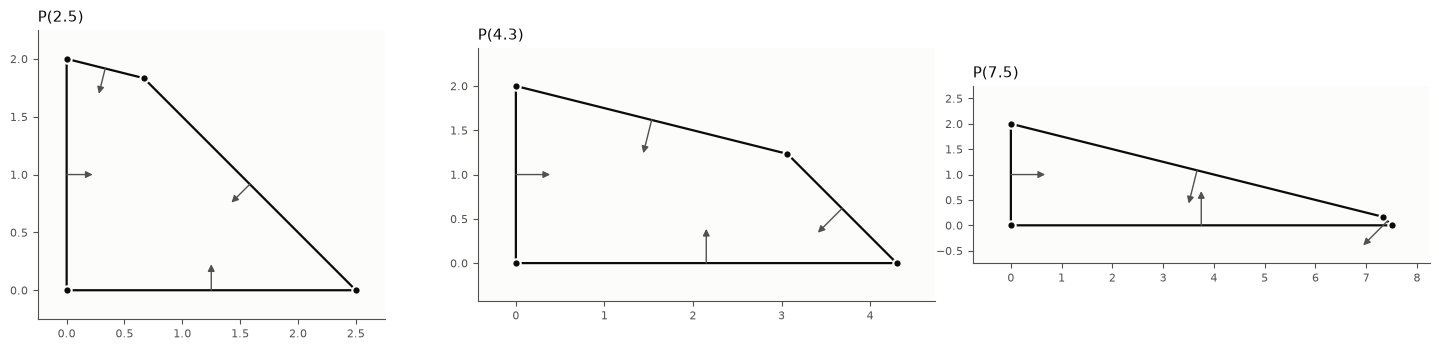

In [2]:
def P(lam, k=12):
    lam = Fraction(lam)
    yv = (8 - lam) / 3
    return Polygon([(0, 0), (lam, 0), (lam - yv, yv), (0, 2)], labels=(1, k, k, k), name=f'P({float(lam):g})')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, lam in zip(axes, ('5/2', '43/10', '15/2')):
    viz.plot_polygon(P(lam), ax=ax, labels=False, vertex_labels=False)
fig.tight_layout()

## 2. Stability across λ

The crease-stability margin min L(f)/∫_∂P f dσ (notebook 01, §5) along the family, and at the two limiting triangles. Negative means unstable; there the crease search also finds an exact rational certificate.

λ =  2.100: margin +0.0696
λ =  2.500: margin +0.0625
λ =  3.000: margin +0.0487
λ =  3.500: margin +0.0323


λ =  4.000: margin +0.0149
λ =  4.200: margin +0.0079
λ =  4.300: margin +0.0028


λ =  4.400: margin -0.0167   certified unstable
λ =  4.500: margin -0.0452   certified unstable
λ =  5.000: margin -0.3614   certified unstable
λ =  5.500: margin -0.9486   certified unstable


λ =  6.000: margin -1.6566   certified unstable


λ =  6.500: margin -2.2965   certified unstable


λ =  7.000: margin -2.5812   certified unstable


λ =  7.500: margin -1.9905   certified unstable


λ =  7.800: margin -0.7297   certified unstable


λ =  7.900: margin -0.0500   certified unstable
λ =  7.950: margin +0.0142


λ =  7.999: margin +0.0198


T2 (λ ≤ 2): +0.0704    T1 (λ ≥ 8): +0.0199


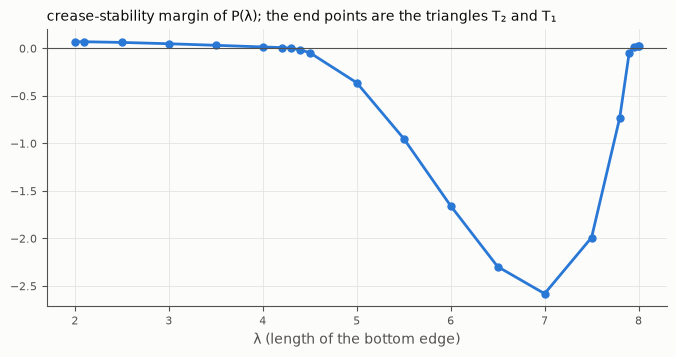

In [3]:
T1 = Polygon([(0, 0), (8, 0), (0, 2)], labels=(1, 12, 12), name='T1')
T2 = Polygon([(0, 0), (2, 0), (0, 2)], labels=(1, 12, 12), name='T2')
lams = [Fraction(v) for v in ('21/10', '5/2', '3', '7/2', '4', '42/10', '43/10', '44/10', '45/10', '5', '11/2', '6',
                               '13/2', '7', '15/2', '78/10', '79/10', '795/100', '7999/1000')]
margins = []
for lam in lams:
    r = crease_search(P(lam), n_angles=180)
    margins.append(r.best_margin)
    print(f'λ = {float(lam):6.3f}: margin {r.best_margin:+.4f}' + ('   certified unstable' if r.unstable else ''))
mT1, mT2 = crease_search(T1).best_margin, crease_search(T2).best_margin
print(f'T2 (λ ≤ 2): {mT2:+.4f}    T1 (λ ≥ 8): {mT1:+.4f}')

ax = viz._line_axes(None, figsize=(8, 3.6))
ax.plot([2] + [float(l) for l in lams] + [8], [mT2] + margins + [mT1], 'o-', color='#2a78d6', lw=2, ms=5)
ax.axhline(0, color=viz.INK_2, lw=0.8)
ax.set_xlabel('λ (length of the bottom edge)', color=viz.INK_2)
ax.set_title('crease-stability margin of P(λ); the end points are the triangles T₂ and T₁', loc='left', fontsize=10, color=viz.INK);

Bisection on the sign of the margin locates the two thresholds. Near λ = 8 small blow-ups of T₁ stay stable, as Arezzo–Pacard-type gluing would predict, until the exceptional divisor reaches lattice length about 0.031. (Just below λ** the sampled margin is −3·10⁻⁵ but no exact certificate is found, so the value of λ** is a numerical estimate; well inside the window, instability is certified exactly.)

In [4]:
def bisect(lo, hi, unstable_at_hi, steps=12):
    for _ in range(steps):
        mid = (lo + hi) / 2
        neg = crease_search(P(mid), n_angles=240).best_margin < 0
        if neg == unstable_at_hi:
            hi = mid
        else:
            lo = mid
    return lo, hi

lo, hi = bisect(Fraction(4), Fraction(9, 2), True)
print(f'λ*  ∈ [{float(lo):.5f}, {float(hi):.5f}]   (stable below, unstable above)')
lo2, hi2 = bisect(Fraction(795, 100), Fraction(79, 10), True)
print(f'λ** ∈ [{float(hi2):.5f}, {float(lo2):.5f}]   (unstable below, stable above);  exceptional divisor of T1 at λ**: '
      f'lattice length {(8 - float(lo2)) / 3:.4f}')

λ*  ∈ [4.31750, 4.31763]   (stable below, unstable above)


λ** ∈ [7.90741, 7.90742]   (unstable below, stable above);  exceptional divisor of T1 at λ**: lattice length 0.0309


## 3. The threshold, exactly

At λ*, L ≥ 0 on all creases and L = 0 on one, so that crease is also a critical point of L in its offset s and direction. Write the line as x + m y = s, Ω = P ∩ {x + m y ≥ s} for the piece it cuts off, and L_Ω(g) = ∫_{∂P∩Ω} g dσ − ∫_Ω A_ext g dμ. Since ℓ = x + m y − s vanishes on the line, the three conditions L = ∂_s L = ∂_m L = 0 say exactly that L_Ω(1) = L_Ω(x) = L_Ω(y) = 0: A_ext(P) is the extremal affine function of the piece Ω with *zero* boundary measure on the cut (and then also of the complementary piece). This is the semistable splitting of Donaldson's Conjecture 7.2.3 (as discussed by Apostolov–Auvray–Sektnan, arXiv:1711.08424).

In the combinatorial cell at hand (the line crosses the bottom and top edges and cuts off the corner of the right edge) these are three polynomial equations in (λ, m, s), solved here to 60 digits.

In [5]:
lam_, m_, s_, x, y, t = sp.symbols('lambda m s x y t', real=True)
c0, c1, c2 = sp.symbols('c0 c1 c2')
yv = (8 - lam_) / 3
V = [(0, 0), (lam_, 0), (lam_ - yv, yv), (0, 2)]
labels, dirs = [1, 12, 12, 12], [(1, 0), (-1, 1), (-4, 1), (0, -1)]

def seg(p, q, f):
    g = sp.expand(f.subs({x: p[0] + t * (q[0] - p[0]), y: p[1] + t * (q[1] - p[1])}, simultaneous=True))
    return sp.Poly(g, t).integrate().eval(1)

def area_int(verts, f):
    F = sp.integrate(sp.expand(f), x)
    return sum((verts[(i + 1) % len(verts)][1] - verts[i][1]) * seg(verts[i], verts[(i + 1) % len(verts)], F) for i in range(len(verts)))

def sigma_len(p, q, k):
    e = dirs[k]
    return ((q[0] - p[0]) * e[0] + (q[1] - p[1]) * e[1]) / (e[0]**2 + e[1]**2) / labels[k]

basis = [sp.Integer(1), x, y]
G = sp.Matrix([[area_int(V, basis[i] * basis[j]) for j in range(3)] for i in range(3)])
b = sp.Matrix([sum(sigma_len(V[k], V[(k + 1) % 4], k) * seg(V[k], V[(k + 1) % 4], g) for k in range(4)) for g in basis])
p_ = (s_, sp.Integer(0)); yq = (8 - s_) / (4 - m_); q_ = (8 - 4 * yq, yq)
Omega = [p_, V[1], V[2], q_]
pieces = [(p_, V[1], 0), (V[1], V[2], 1), (V[2], q_, 2)]
A = c0 + c1 * x + c2 * y
eqs = [sum(sigma_len(a, bb, k) * seg(a, bb, g) for a, bb, k in pieces) - area_int(Omega, A * g) for g in basis]

mpmath.mp.dps = 60
Gf, bf = sp.lambdify(lam_, G, 'mpmath'), sp.lambdify(lam_, b, 'mpmath')
ef = sp.lambdify((lam_, m_, s_, c0, c1, c2), eqs, 'mpmath')
def balance(L, M, S):
    cc = mpmath.lu_solve(Gf(L), bf(L))
    return ef(L, M, S, cc[0], cc[1], cc[2])

th0 = mpmath.radians(mpmath.mpf('51.95'))
LAM, M, S = mpmath.findroot(balance, (mpmath.mpf('4.3176'), mpmath.tan(th0), mpmath.mpf('2.0144') / mpmath.cos(th0)))
print('λ* =', mpmath.nstr(LAM, 45))
print('m* =', mpmath.nstr(M, 45), '   θ* =', mpmath.nstr(mpmath.degrees(mpmath.atan(M)), 15), '°')
print('s* =', mpmath.nstr(S, 45))
print('residuals:', [mpmath.nstr(v, 3) for v in balance(LAM, M, S)])
print(f'the crease meets the bottom edge at x = {float(S):.6f} and the top edge at y = {float((8 - S) / (4 - M)):.6f}')

λ* = 4.31756909532834809204441390389044186399657825
m* = 1.27756622611491836177726613447388268913200797    θ* = 51.9483529981744 °
s* = 3.27402233061765305692221958468055229036991527
residuals: ['-2.49e-60', '1.37e-59', '-2.89e-59']
the crease meets the bottom edge at x = 3.274022 and the top edge at y = 1.735939


This agrees with the bisection of §2, which only used the sign of the sampled margin: the balance equations, derived from criticality of L, pick out the same threshold.

**The critical direction is irrational.** The continued fraction of m* does not terminate within 30 terms (so m* is not a rational number of denominator below about 10²⁵), and integer-relation search finds no polynomial of degree ≤ 8 with coefficients ≤ 10⁶ for m* or λ*. (Both are algebraic, being solutions of a polynomial system.) Donaldson's Prop. 6.1 makes destabilizing creases rational strictly inside the unstable region; at the threshold itself the balanced crease need not be, and here it is not.

In [6]:
def cf(v, n=30):
    out = []
    for _ in range(n):
        a = mpmath.floor(v); out.append(int(a)); v = v - a
        if abs(v) < mpmath.mpf(10)**-40: break
        v = 1 / v
    return out

print('continued fraction of m*:', cf(M))
print('continued fraction of λ*:', cf(LAM))
for name, v in (('m*', M), ('λ*', LAM)):
    found = next((mpmath.findpoly(v, deg, maxcoeff=10**6) for deg in (2, 3, 4, 6, 8) if mpmath.findpoly(v, deg, maxcoeff=10**6)), None)
    print(f'{name}: integer polynomial of degree ≤ 8, coefficients ≤ 1e6:', found)

continued fraction of m*: [1, 3, 1, 1, 1, 1, 13, 1, 45, 7, 5, 11, 2, 4, 1, 10, 2, 3, 1, 4, 1, 2, 1, 2, 13, 3, 1, 3, 1, 1]
continued fraction of λ*: [4, 3, 6, 1, 2, 1, 1, 29, 3, 4, 7, 2, 1, 2, 9, 1, 1, 1, 1, 3, 48, 11, 1, 2, 1, 4, 1, 2, 1, 1]
m*: integer polynomial of degree ≤ 8, coefficients ≤ 1e6: None


λ*: integer polynomial of degree ≤ 8, coefficients ≤ 1e6: None


## 4. Following the extremal metrics up to λ*

For λ = λ* − ε, solve for the extremal metric (degrees 20 and 24, to check convergence) and look along the normal line through the midpoint of the critical crease (the exact line from §3):

- **circle length** F = 2π √(nᵀ K n): the length of the orbit of the Killing field n·∂_θ dual to the crease (K = (Hess u)⁻¹);
- **arc length** r along the normal line, r = ∫ √(u_nn), with r = 0 on the crease;
- **base length** B: the metric length of the chord parallel to the crease, ∫ √(u_ττ) along it;
- |Ric|² along the normal line.

In the torus fibration, the 3-manifold over a chord is S³ or a lens space (the torus collapses to circles at the two ends of the chord); F and B describe its shape.

In [7]:
NORM = math.hypot(1, float(M))
N = np.array([1, float(M)]) / NORM
S_N = float(S) / NORM

def chord(Q, n, s):
    pts = []
    for e in Q.edges:
        p, q = np.array(e.start, float), np.array(e.end, float)
        a, bb = n @ p - s, n @ q - s
        if a * bb <= 0 and a != bb:
            pts.append(p + a / (a - bb) * (q - p))
    return pts[0], pts[1]

def profile(Q, metric, nt=801, margin=2e-3):
    U = np.array([e.normal for e in Q.edges], float); lv = np.array([float(e.constant) for e in Q.edges])
    p, q = chord(Q, N, S_N); c = (p + q) / 2
    lo, hi = -np.inf, np.inf
    for u, l in zip(U, lv):
        a, bb = u @ N, u @ c - l
        if abs(a) > 1e-14:
            lo, hi = (max(lo, -bb / a), hi) if a > 0 else (lo, min(hi, -bb / a))
    ts = np.linspace(lo + margin, hi - margin, nt)
    pts = c[None, :] + ts[:, None] * N[None, :]
    H = metric._hessian_derivatives(pts[:, 0], pts[:, 1])[0]
    unn = np.einsum('a,nab,b->n', N, H, N)
    F = 2 * np.pi * np.sqrt(np.einsum('a,nab,b->n', N, np.linalg.inv(H), N))
    sq = np.sqrt(np.maximum(unn, 0))
    r = np.concatenate([[0], np.cumsum((sq[1:] + sq[:-1]) / 2 * np.diff(ts))])
    r -= r[int(np.argmin(np.abs(ts)))]
    R = metric.ricci_norm_sq(pts[:, 0], pts[:, 1])
    B = np.full(nt, np.nan)
    for j in range(0, nt, 20):
        a, bb = chord(Q, N, S_N + ts[j])
        sg = np.linspace(0, 1, 401)[1:-1]; wgt = (1 - np.cos(np.pi * sg)) / 2
        cp = a[None, :] + wgt[:, None] * (bb - a)[None, :]
        Hc = metric._hessian_derivatives(cp[:, 0], cp[:, 1])[0]
        dvec = (bb - a) / np.linalg.norm(bb - a)
        B[j] = np.trapezoid(np.sqrt(np.einsum('a,nab,b->n', dvec, Hc, dvec)) * np.linalg.norm(bb - a) * np.pi / 2 * np.sin(np.pi * sg), sg)
    return dict(t=ts, r=r, F=F, R=R, B=B)

eps_list = [0.3, 0.1, 0.03, 0.01, 0.003]
profiles = {}
print(f"{'λ*−λ':>7} {'d':>3} {'F at crease':>12} {'total arc length':>17} {'B at crease':>12} {'defect L²':>10}")
for eps in eps_list:
    Q = P(Fraction(float(LAM) - eps).limit_denominator(10**9))
    prev = None
    for d in (20, 24):
        r = ExtremalSolver(Q, degree=d).solve(c0=prev)
        pr = profile(Q, r.metric)
        profiles[(eps, d)] = pr
        i0 = int(np.argmin(np.abs(pr['t'])))
        Bc = np.nanmean(pr['B'][max(0, i0 - 20): i0 + 21])
        print(f"{eps:>7} {d:>3} {pr['F'][i0]:>12.4f} {pr['r'][-1] - pr['r'][0]:>17.3f} {Bc:>12.3f} {r.defect(order=40)['L2']:>10.2e}")
        prev = r

   λ*−λ   d  F at crease  total arc length  B at crease  defect L²


    0.3  20       0.7493            13.911        5.762   2.46e-01


    0.3  24       0.7493            13.908        5.755   1.27e-01


    0.1  20       0.4492            17.699        5.638   3.11e-01


    0.1  24       0.4466            17.704        5.634   1.54e-01


   0.03  20       0.2716            22.607        5.576   1.20e+00


   0.03  24       0.2602            22.717        5.581   7.12e-01


   0.01  20       0.2041            26.376        5.540   2.55e+00


   0.01  24       0.1847            26.910        5.546   1.79e+00


  0.003  20       0.1779            28.635        5.522   3.58e+00


  0.003  24       0.1541            29.732        5.527   2.74e+00


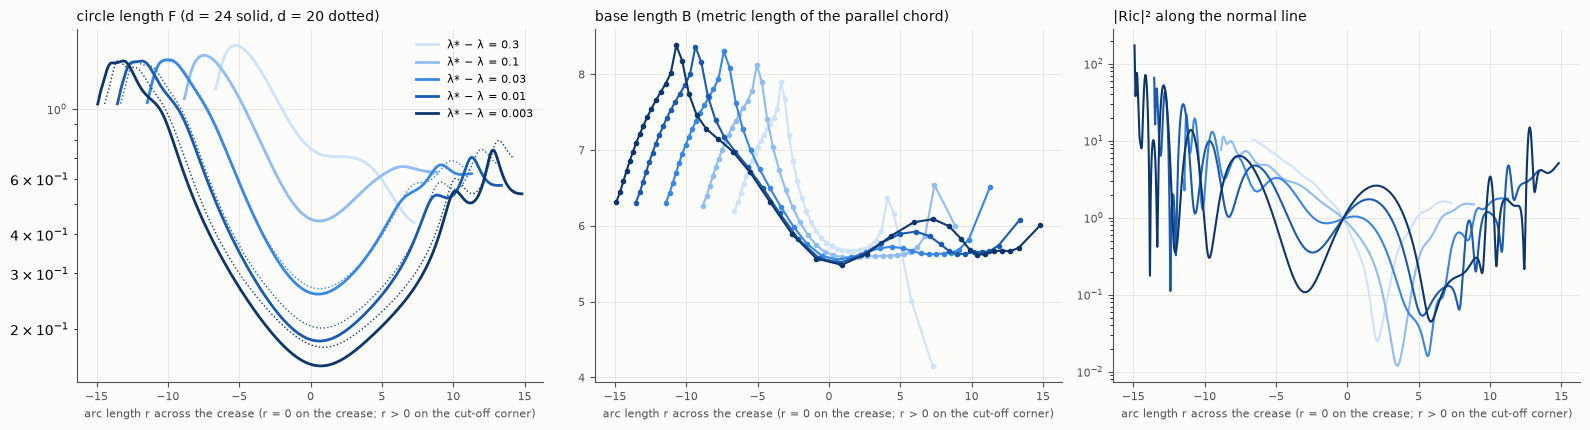

In [8]:
cols = ['#cde2fb', '#8fbcf2', '#3987e5', '#1a5bb0', '#0d366b']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
fig.patch.set_facecolor(viz.SURFACE)
for ax in axes:
    viz._line_axes(ax)
for eps, col in zip(eps_list, cols):
    pr, pr20 = profiles[(eps, 24)], profiles[(eps, 20)]
    axes[0].semilogy(pr['r'], pr['F'], color=col, lw=2, label=f'λ* − λ = {eps}')
    axes[0].semilogy(pr20['r'], pr20['F'], color=col, lw=1, ls=':')
    ok = ~np.isnan(pr['B'])
    axes[1].plot(pr['r'][ok], pr['B'][ok], 'o-', color=col, ms=3, lw=1.5)
    axes[2].semilogy(pr['r'], pr['R'], color=col, lw=1.5)
titles = ('circle length F (d = 24 solid, d = 20 dotted)', 'base length B (metric length of the parallel chord)', '|Ric|² along the normal line')
for ax, ttl in zip(axes, titles):
    ax.set_title(ttl, loc='left', fontsize=10, color=viz.INK)
    ax.set_xlabel('arc length r across the crease (r = 0 on the crease; r > 0 on the cut-off corner)', color=viz.INK_2, fontsize=8)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## 5. What this shows

- **A neck forms along the critical crease.** The arc length across the polygon through the crease grows by about 8 per decade of λ* − λ, consistent with a logarithmic divergence at λ*.
- **The dual circle collapses there.** F develops a well centred on the crease that deepens as λ ↑ λ*, with roughly exponential walls (log-slope about −0.2 on the side of the large piece, shallower on the cut-off corner).
- **The base does not grow.** B stays near 5.6 across the neck for every λ.
- **Curvature stays moderate in the neck** (|Ric|² of order 1); the large values in the plot are at the far end of the line, next to ∂P, and are not converged in d.

Together: collapse with bounded curvature along the balanced crease, with a fixed base. This argues against ALF ends (whose base grows) and fits finite-volume, cusp-like ends, as in Donaldson's splitting picture; in the toric setting all these metrics have the same total volume (2π)² μ(P) anyway. It is also consistent with the classification of scalar-flat toric instantons (B. Weber, J. Geom. 2023), which rules out curvature blow-up in the interior but not collapse.

**The irrational direction.** The collapsing Killing field is n·∂_θ with n ∝ (1, m*), m* irrational, so its orbits are dense lines in the torus fibres, not circles. A flat 2-torus in which an irrational direction shrinks collapses to a point, not to a circle. If the neck becomes infinitely long at λ*, its cross-section (S³ or a lens space over the chord) would then collapse to an interval rather than to a 2-sphere: not a Poincaré-type cusp along a divisor. This regime is far from what is resolved here (F ≥ 0.15).

**Caveats and open questions.**
- Resolution: the scalar-curvature defect S − A_ext converges slowly in d for these labelled metrics, and gets worse towards λ*: L² ≈ 0.13 at λ* − λ = 0.3 but 0.7–2.7 for λ* − λ ≤ 0.03 (d = 24), concentrated near ∂P. The second-order quantities in the table (F, arc length, B) are much better behaved: they agree between d = 20 and 24 to a few digits for λ* − λ ≥ 0.1, and to 10–15% closer to λ*. So the trends are reliable; the values closest to λ* are not.
- Whether the walls of the F-well settle to fixed exponential rates (Poincaré-type ends) is not determined: the fitted log-slopes still drift as λ → λ*.
- The other threshold λ** (small blow-ups of T₁ becoming unstable) has not been followed in the same way.